# Intelligent Document Classification System
**SparkIIT AI Project 1** | NLP, Feature Extraction, Classification, Model Evaluation

**Objective:** Build an AI model that classifies text documents into topic categories and evaluate it with Accuracy, Precision, Recall and F1-Score.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
print("Libraries loaded")

Libraries loaded


## 1. Collect the dataset
20 Newsgroups (built into scikit-learn), 6 categories. Headers, footers and quoted replies are removed so the model learns from the real text only.

In [2]:
cats = ['sci.space', 'rec.sport.hockey', 'comp.graphics', 'talk.politics.guns', 'rec.autos', 'sci.med']
data = fetch_20newsgroups(subset='all', categories=cats, remove=('headers', 'footers', 'quotes'))
df = pd.DataFrame({'text': data.data, 'label': [data.target_names[i] for i in data.target]})
df = df[df['text'].str.strip().str.len() > 0].reset_index(drop=True)
print("Total documents:", len(df))
df.head()

Total documents: 5668


,text,label
0,": Currently, I use a shareware program called ...",comp.graphics
1,\n\nMore like Philadelphia making dust out of...,rec.sport.hockey
2,"\nOff the top of my head, I might try:\n\nGive...",comp.graphics
3,"\nIf I'm not mistaken, San Jose had more wins ...",rec.sport.hockey
4,\nPlaymation is available direct from Anjon & ...,comp.graphics


## 2. Explore the data

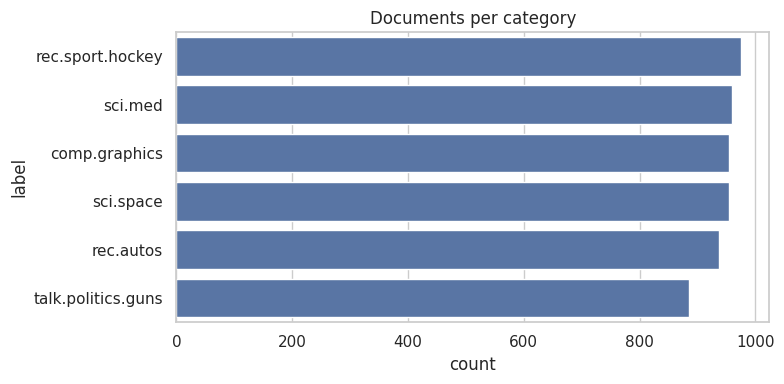

count     5668.000000
mean       184.685780
std        520.366119
min          1.000000
25%         43.000000
50%         85.000000
75%        163.000000
max      11251.000000
Name: text, dtype: float64


In [3]:
plt.figure(figsize=(8, 4))
sns.countplot(y='label', data=df, order=df['label'].value_counts().index)
plt.title('Documents per category')
plt.tight_layout()
plt.savefig('fig_class_distribution.png', dpi=150)
plt.show()
print(df['text'].str.split().str.len().describe())

## 3. Text cleaning and tokenization
Lowercase, keep only letters, tokenize into words, remove stop words.

In [4]:
def clean_text(text):
    tokens = re.findall(r'[a-z]{2,}', text.lower())
    tokens = [t for t in tokens if t not in ENGLISH_STOP_WORDS]
    return ' '.join(tokens)

df['clean'] = df['text'].apply(clean_text)
df = df[df['clean'].str.len() > 0].reset_index(drop=True)
print("Before:", df['text'].iloc[0][:200])
print("After :", df['clean'].iloc[0][:200])

Before: : Currently, I use a shareware program called Graphics Workshop.
: What kinds of things will Hijaak do that these shareware programs
: will not do?

I also use Graphic Workshop and the only difference
After : currently use shareware program called graphics workshop kinds things hijaak shareware programs use graphic workshop differences know hijaak screen capture capabilities acn convert couple file formats


## 4. Train/test split and TF-IDF feature extraction
The vectorizer is fitted on training data only, to avoid data leakage.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print("Train matrix:", Xtr.shape, "| Test matrix:", Xte.shape)

Train matrix: (4524, 20000) | Test matrix: (1131, 20000)


## 5. Train and compare three models

In [6]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM': LinearSVC(),
}
rows = []
for name, model in models.items():
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='weighted'),
        'Recall': recall_score(y_test, pred, average='weighted'),
        'F1-Score': f1_score(y_test, pred, average='weighted'),
    })
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Naive Bayes,0.9045,0.9058,0.9045,0.9044
Logistic Regression,0.8974,0.8977,0.8974,0.8974
Linear SVM,0.9089,0.9090,0.9089,0.9088


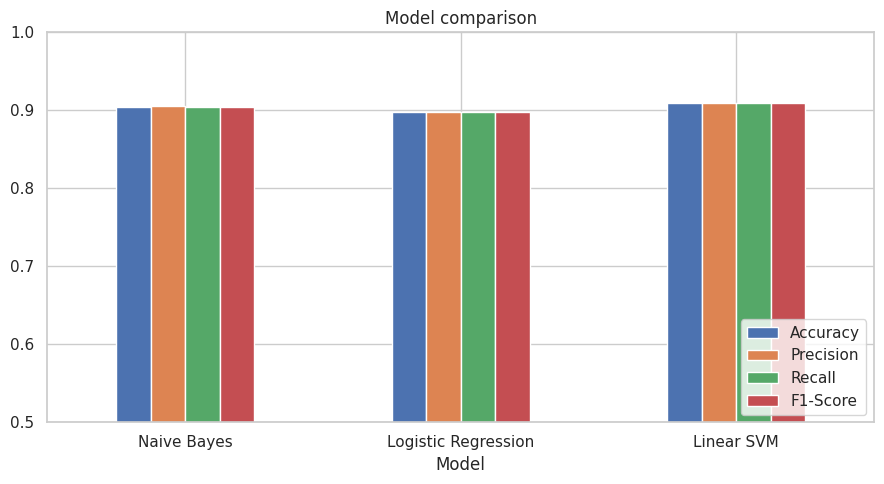

In [7]:
results.plot(kind='bar', figsize=(9, 5), ylim=(0.5, 1.0))
plt.title('Model comparison')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('fig_model_comparison.png', dpi=150)
plt.show()

## 6. Optimize the best model
GridSearchCV on Linear SVM (regularization strength C).

In [8]:
base_f1 = results.loc['Linear SVM', 'F1-Score']
grid = GridSearchCV(LinearSVC(), {'C': [0.05, 0.1, 0.5, 1, 2, 5]}, cv=3, scoring='f1_weighted')
grid.fit(Xtr, y_train)
best = grid.best_estimator_
pred_best = best.predict(Xte)
tuned_f1 = f1_score(y_test, pred_best, average='weighted')
print("Best params:", grid.best_params_)
print(f"F1 before tuning: {base_f1:.4f} | after tuning: {tuned_f1:.4f}")
print(f"Tuned accuracy: {accuracy_score(y_test, pred_best):.4f}")

Best params: {'C': 0.5}
F1 before tuning: 0.9088 | after tuning: 0.9105
Tuned accuracy: 0.9107


## 7. Final evaluation

                    precision    recall  f1-score   support

     comp.graphics       0.91      0.95      0.93       190
         rec.autos       0.90      0.91      0.91       187
  rec.sport.hockey       0.95      0.94      0.95       194
           sci.med       0.89      0.91      0.90       192
         sci.space       0.90      0.88      0.89       191
talk.politics.guns       0.91      0.86      0.89       177

          accuracy                           0.91      1131
         macro avg       0.91      0.91      0.91      1131
      weighted avg       0.91      0.91      0.91      1131



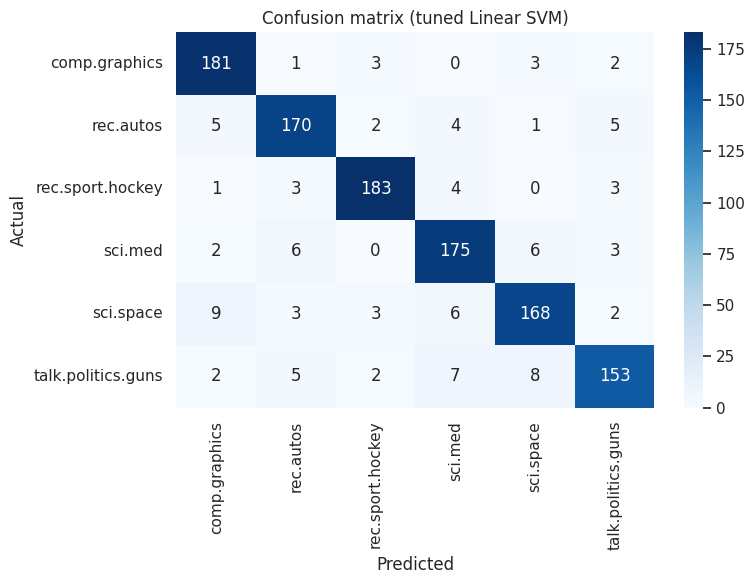

In [9]:
print(classification_report(y_test, pred_best))
classes = best.classes_
cm = confusion_matrix(y_test, pred_best, labels=classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (tuned Linear SVM)')
plt.tight_layout()
plt.savefig('fig_confusion_matrix.png', dpi=150)
plt.show()

## 8. Result analysis
Which categories get confused, and which words drive each prediction.

In [10]:
pairs = [(classes[i], classes[j], cm[i, j]) for i in range(len(classes)) for j in range(len(classes)) if i != j]
pairs = sorted(pairs, key=lambda x: -x[2])[:5]
print("Most confused pairs (actual -> predicted, count):")
for a, p, c in pairs:
    print(f"  {a} -> {p}: {c}")

feat = np.array(tfidf.get_feature_names_out())
print("\nTop words per category:")
for i, c in enumerate(classes):
    top = feat[np.argsort(best.coef_[i])[-8:][::-1]]
    print(f"  {c}: {', '.join(top)}")

Most confused pairs (actual -> predicted, count):
  sci.space -> comp.graphics: 9
  talk.politics.guns -> sci.space: 8
  talk.politics.guns -> sci.med: 7
  sci.med -> rec.autos: 6
  sci.med -> sci.space: 6

Top words per category:
  comp.graphics: graphics, image, file, files, computer, version, pov, program
  rec.autos: car, cars, engine, dealer, ford, oil, radar, bmw
  rec.sport.hockey: game, hockey, team, games, nhl, season, puck, roger
  sci.med: doctor, medical, health, msg, disease, treatment, photography, blood
  sci.space: space, orbit, shuttle, launch, moon, earth, sky, nasa
  talk.politics.guns: gun, guns, weapons, fbi, firearms, government, koresh, house


## 9. Test on unseen documents

In [11]:
samples = [
    "NASA launched a new satellite to study the moon and Mars",
    "The goalie made an amazing save in overtime of the playoff game",
    "My new graphics card renders 3D scenes and images much faster",
    "The doctor prescribed antibiotics for the infection and fever",
    "This car has a powerful engine and great fuel mileage",
    "The debate over gun control laws continues in congress",
]
preds = best.predict(tfidf.transform([clean_text(s) for s in samples]))
for s, p in zip(samples, preds):
    print(f"[{p}]  {s}")

[sci.space]  NASA launched a new satellite to study the moon and Mars
[rec.sport.hockey]  The goalie made an amazing save in overtime of the playoff game
[comp.graphics]  My new graphics card renders 3D scenes and images much faster
[sci.med]  The doctor prescribed antibiotics for the infection and fever
[rec.autos]  This car has a powerful engine and great fuel mileage
[talk.politics.guns]  The debate over gun control laws continues in congress


In [12]:
!pip -q install sentence-transformers
from sentence_transformers import SentenceTransformer
enc = SentenceTransformer('all-MiniLM-L6-v2')
Etr = enc.encode(df.loc[X_train.index, 'text'].tolist(), batch_size=64, show_progress_bar=True)
Ete = enc.encode(df.loc[X_test.index, 'text'].tolist(), batch_size=64)
emb = LogisticRegression(max_iter=2000).fit(Etr, y_train)
p = emb.predict(Ete)
print(f"Embeddings + LR | Accuracy: {accuracy_score(y_test, p):.4f} | F1: {f1_score(y_test, p, average='weighted'):.4f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/71 [00:00<?, ?it/s]

Embeddings + LR | Accuracy: 0.8930 | F1: 0.8930


In [16]:
import joblib, sklearn
joblib.dump({'tfidf': tfidf, 'model': best}, 'doc_classifier.joblib')
print(sklearn.__version__)

1.6.1


In [18]:
import joblib, sklearn, sys
from google.colab import files
tfidf.stop_words_ = None
joblib.dump({'tfidf': tfidf, 'model': best}, 'doc_classifier.joblib')
print("sklearn:", sklearn.__version__, "| python:", sys.version.split()[0])
files.download('doc_classifier.joblib')

sklearn: 1.6.1 | python: 3.13.16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
TF-IDF features with a tuned Linear SVM gave the strongest results. Fill in your final numbers and observations from the outputs above in the report.